# 07 · From predictions to decisions: two decision cards

A prediction alone changes nothing. A **decision card** is an 11-line note that says what the business does with the number, and whether it is worth it. We write one card for each prediction, using the predictions saved by notebooks 06a and 06b **on the held-out months (October to December)**.

Every number on a card below is **computed by code** and written into the text, so the cards cannot drift from the data. The value is always compared with **the dumb answer** or with **picking at random**.

**Two assumptions come from the business, not from the data**, and must be confirmed with the agency:
1. it can warn about **1 flight in 5** (first card);
2. it can check the connections of **1 flight in 20** (second card).

The data contains no prices, so **no euro value is invented**: the value is stated in flights and clients reached.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
from src import common, viz

import numpy as np
import pandas as pd
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import Markdown, display

common.require_processed("flights_clean.parquet", "features.parquet", "predictions_test_late.parquet", "predictions_test_second.parquet", "destination_groups.parquet")
viz.apply_style()
pd.set_option("display.width", 170)
WARN_SHARE = 0.20      # assumption 1: the agency can warn about 1 flight in 5
CHECK_SHARE = 0.05     # assumption 2: the agency can check connections for 1 flight in 20
LONG_DELAY = 45        # a "long" delay, in minutes: where connections start to break

In [2]:
meta = pd.read_parquet(common.PROC / "flights_clean.parquet", columns=["row_id", "sched_dep_dt", "dest", "carrier", "origin", "hour"])
dest_groups = pd.read_parquet(common.PROC / "destination_groups.parquet")[["dest", "group_name"]]
late = pd.read_parquet(common.PROC / "predictions_test_late.parquet").merge(meta, on="row_id").merge(dest_groups, on="dest")
sec = pd.read_parquet(common.PROC / "predictions_test_second.parquet").merge(meta, on="row_id")
late["week_start"] = late["sched_dep_dt"].dt.to_period("W").dt.start_time
sec["week_start"] = sec["sched_dep_dt"].dt.to_period("W").dt.start_time
feat = pd.read_parquet(common.PROC / "features.parquet", columns=["part", "dep_delay", "prev_known"])
usual = float(feat.loc[feat["part"].isin(["fit", "valid"]), "dep_delay"].median())   # the dumb answer of the second prediction
res_a = pd.read_csv(common.REPORTS / "06a_results.csv").pivot(index="model", columns="metric", values="value")
res_b = pd.read_csv(common.REPORTS / "06b_results.csv").pivot(index="model", columns="metric", values="value")
errors_a = pd.read_csv(common.REPORTS / "06a_group_errors.csv")
errors_b = pd.read_csv(common.REPORTS / "06b_group_errors.csv")
calib = pd.read_csv(common.REPORTS / "06a_calibration.csv")
findings = pd.read_csv(common.REPORTS / "02_findings.csv")
airline_names = pd.read_csv(common.RAW / "airlines.csv").set_index("carrier")["name"].str.replace(r"\s+(Inc\.|Co\.|Corporation)$", "", regex=True)
print(f"first prediction: {len(late):,} held-out flights | second: {len(sec):,} flights that left | dumb answer of the second: {usual:.0f} minutes")

first prediction: 104,469 held-out flights | second: 104,245 flights that left | dumb answer of the second: -2 minutes


## Card 1 · Will this flight be late or cancelled?
### The cut-off and the value, computed
**Cut-off by capacity:** rank the flights by risk and warn about the riskiest 20%. We never use a fixed probability: in notebook 06a the risk scores ran too high in the calm months (about 21% predicted against 14% real), so a fixed probability would warn about the wrong number of flights.

In [3]:
def top_share(score, share):
    """Boolean flags for the highest `share` of scores (ties broken with a fixed seed)."""
    k = int(round(len(score) * share))
    jitter = np.random.default_rng(common.SEED).random(len(score)) * 1e-9
    flagged = np.zeros(len(score), dtype=bool)
    flagged[np.argsort(-(np.asarray(score, dtype=float) + jitter), kind="stable")[:k]] = True
    return flagged

y1 = late["y_true"].to_numpy()
flag1 = top_share(late["risk"], WARN_SHARE)
n1, k1 = len(late), int(flag1.sum())
hits1 = int((flag1 & (y1 == 1)).sum())
precision1, recall1, base1 = hits1 / k1, hits1 / y1.sum(), y1.mean()
random_recall1 = k1 / n1                       # picking k flights at random reaches this share of late flights on average
threshold1 = float(late.loc[flag1, "risk"].min())
late["date"] = late["sched_dep_dt"].dt.date
# Rule 1, what a live system can really run: warn a flight when its risk is above the cut-off taken from the risk scores of the previous 7 days
# (scores only: no outcomes, no flights that have not been scheduled yet). It starts on the 8th day of the held-out months.
days = np.array(sorted(late["date"].unique()))
cutoff_by_day = {d: late.loc[late["date"].isin(days[i - 7:i]), "risk"].quantile(1 - WARN_SHARE) for i, d in enumerate(days) if i >= 7}
live = late[late["date"].isin(cutoff_by_day)]
live_flag = live["risk"].to_numpy() >= live["date"].map(cutoff_by_day).to_numpy().astype(float)
live_y = live["y_true"].to_numpy()
share_live, recall_live = float(live_flag.mean()), float((live_flag & (live_y == 1)).sum() / live_y.sum())
precision_live = float((live_flag & (live_y == 1)).sum() / live_flag.sum())
# Rule 2, the strict case: each hour is ranked on its own, with no history at all (only that hour's flights)
late["hour_start"] = late["sched_dep_dt"].dt.floor("h")
flag_hour = pd.Series(False, index=late.index)
for _, g in late.groupby("hour_start"):
    flag_hour.loc[g.index] = top_share(g["risk"].to_numpy(), WARN_SHARE)
recall_hour = float((flag_hour.to_numpy() & (y1 == 1)).sum() / y1.sum())
value_first = pd.DataFrame([dict(share_flagged=round(k1 / n1, 4), flagged=k1, hits=hits1, precision=round(precision1, 4), recall=round(recall1, 4),
                                 random_recall=round(random_recall1, 4), lift=round(recall1 / random_recall1, 3), risk_threshold=round(threshold1, 3), base_rate=round(base1, 4),
                                 share_live_rule=round(share_live, 4), recall_live_rule=round(recall_live, 4), precision_live_rule=round(precision_live, 4),
                                 recall_ranked_per_hour=round(recall_hour, 4))])
common.REPORTS.mkdir(parents=True, exist_ok=True)
value_first.to_csv(common.REPORTS / "07_value_first.csv", index=False)
print(value_first.T.to_string(header=False))

share_flagged               0.2000
flagged                 20894.0000
hits                     5947.0000
precision                   0.2846
recall                      0.4050
random_recall               0.2000
lift                        2.0250
risk_threshold              0.3050
base_rate                   0.1406
share_live_rule             0.1972
recall_live_rule            0.4050
precision_live_rule         0.2843
recall_ranked_per_hour      0.3414


**Per type of destination (notebook 03).** Where do the warnings land, and how many late flights do we reach in each type? This is what lets us give a different action to each type.

In [4]:
late["flagged"] = flag1
by_group = late.groupby("group_name").apply(lambda g: pd.Series({"flights": len(g), "warned_share": g["flagged"].mean(), "late_rate": g["y_true"].mean(),
                                                                "precision": (g["flagged"] & (g["y_true"] == 1)).sum() / max(g["flagged"].sum(), 1),
                                                                "recall": (g["flagged"] & (g["y_true"] == 1)).sum() / max(g["y_true"].sum(), 1)}), include_groups=False)
print(by_group.round(3).to_string())

                                              flights  warned_share  late_rate  precision  recall
group_name                                                                                       
Afternoon build-up routes                     58627.0         0.255      0.165      0.286   0.442
Rare destinations (too few flights to judge)    119.0         0.034      0.084      0.500   0.200
Steady regional routes                        45311.0         0.123      0.107      0.275   0.316
Thin routes with long delays                    412.0         0.920      0.350      0.367   0.965


### Week by week: when must the model be checked again?
The held-out part has only 3 months, so we score it **week by week**. In each week we warn about that week's riskiest 20% and measure how many late flights we reach. **Decision:** re-check the model when the weekly reach falls below **80% of its median weekly value in the July-to-September validation weeks** (taken from notebook 06a, not from these held-out weeks, so the line is not circular) for two weeks in a row (weeks with at least 5,000 flights).

In [5]:
def week_recall(g):
    flags = top_share(g["risk"], WARN_SHARE)
    return pd.Series({"n": len(g), "value": (flags & (g["y_true"] == 1)).sum() / g["y_true"].sum()})
wk1 = late.groupby("week_start").apply(week_recall, include_groups=False).reset_index()
wk1["n"] = wk1["n"].astype(int)
full1 = wk1[wk1["n"] >= 5000]
valid_weeks = pd.read_csv(common.REPORTS / "06a_valid_weekly_reach.csv")
median_recall = valid_weeks.loc[valid_weeks["n"] >= 5000, "recall_at_20pct"].median()      # from the validation weeks, not from the held-out weeks
trigger1 = 0.8 * median_recall
value_first["recheck_line"] = round(trigger1, 4)
value_first.to_csv(common.REPORTS / "07_value_first.csv", index=False)

def rule_text(n):
    return "would not have fired" if n == 0 else "would have fired once" if n == 1 else f"would have fired {n} times"
below = (full1["value"] < trigger1).astype(int)
twice_in_a_row = int(((below + below.shift(fill_value=0)) == 2).sum())
print(full1.assign(value=full1["value"].round(3)).to_string(index=False))
print(f"\nmedian weekly reach on the validation weeks {median_recall:.1%} | re-check line (80% of it): {trigger1:.1%} | the rule {rule_text(twice_in_a_row)} on the held-out weeks")

week_start    n  value
2023-10-02 8352  0.373
2023-10-09 8185  0.415
2023-10-16 8169  0.366
2023-10-23 8215  0.399
2023-10-30 8300  0.403
2023-11-06 8111  0.395
2023-11-13 8236  0.460
2023-11-20 7526  0.387
2023-11-27 8094  0.385
2023-12-04 7999  0.420
2023-12-11 7978  0.429
2023-12-18 7677  0.431
2023-12-25 6436  0.395

median weekly reach on the validation weeks 36.9% | re-check line (80% of it): 29.5% | the rule would not have fired on the held-out weeks


## Card 2 · How many minutes late will this flight leave?
### The cut-off and the value, computed
**Cut-off by capacity:** the 5% of flights with the highest predicted delay get a connection check. The model predicts the *usual* (median) delay for flights like that one, so its predictions rarely reach 45 minutes by themselves; ranking the flights is what makes it useful here. We then measure how many of the flagged flights really leave **45 minutes or more** late.

In [6]:
y2, pred2 = sec["y_true"].to_numpy(), sec["pred"].to_numpy()
flag2 = top_share(pred2, CHECK_SHARE)
n2, k2 = len(sec), int(flag2.sum())
long2 = y2 >= LONG_DELAY
hits2 = int((flag2 & long2).sum())
precision2, base2, recall2 = hits2 / k2, long2.mean(), hits2 / long2.sum()
mae_model, mae_dumb = float(res_b.loc["gradient_boosting", "mae_minutes"]), float(res_b.loc["dumb_median", "mae_minutes"])
med_model, med_dumb = float(res_b.loc["gradient_boosting", "median_error_minutes"]), float(res_b.loc["dumb_median", "median_error_minutes"])
threshold2 = float(pred2[flag2].min())
value_second = pd.DataFrame([dict(threshold_minutes=round(threshold2, 1), flagged=k2, true_long=hits2, precision_long=round(precision2, 4), base_rate_long=round(base2, 4),
                                  lift=round(precision2 / base2, 3), recall_long=round(recall2, 4), random_recall_long=round(k2 / n2, 4),
                                  mae_model=round(mae_model, 3), mae_dumb=round(mae_dumb, 3), gain_minutes=round(mae_dumb - mae_model, 3),
                                  median_error_model=round(med_model, 3), median_error_dumb=round(med_dumb, 3))])
value_second.to_csv(common.REPORTS / "07_value_second.csv", index=False)
print(value_second.T.to_string(header=False))

threshold_minutes     13.5000
flagged             5212.0000
true_long           1103.0000
precision_long         0.2116
base_rate_long         0.0632
lift                   3.3510
recall_long            0.1675
random_recall_long     0.0500
mae_model             13.1220
mae_dumb              13.2670
gain_minutes           0.1450
median_error_model     4.4760
median_error_dumb      5.0000


**Week by week.** For each week we compare the model's average error with the dumb answer's. **Decision:** re-check the model when it is **no better than the dumb answer for two weeks in a row**.

In [7]:
def week_gain(g):
    return pd.Series({"n": len(g), "value": np.abs(g["y_true"] - usual).mean() - np.abs(g["y_true"] - g["pred"]).mean()})
wk2 = sec.groupby("week_start").apply(week_gain, include_groups=False).reset_index()
wk2["n"] = wk2["n"].astype(int)
full2 = wk2[wk2["n"] >= 5000]
worse = (full2["value"] <= 0).astype(int)
fired2 = int(((worse + worse.shift(fill_value=0)) == 2).sum())
print(full2.assign(value=full2["value"].round(3)).to_string(index=False))
print(f"\nweeks where the model beats the dumb answer: {int((full2['value'] > 0).sum())} of {len(full2)} | times the trigger would have fired: {fired2}")

weekly = pd.concat([wk1.assign(prediction="late_or_cancelled", metric="recall_at_20pct"), wk2.assign(prediction="minutes_late", metric="gain_minutes")])[["prediction", "week_start", "n", "metric", "value"]]
weekly["value"] = weekly["value"].round(4)
weekly.to_csv(common.REPORTS / "07_weekly_scores.csv", index=False)

week_start    n  value
2023-10-02 8344  0.082
2023-10-09 8179 -1.203
2023-10-16 8157 -0.999
2023-10-23 8198  0.117
2023-10-30 8296  0.218
2023-11-06 8103  0.478
2023-11-13 8230  0.693
2023-11-20 7525  0.715
2023-11-27 8091 -0.025
2023-12-04 7997  0.429
2023-12-11 7960  0.781
2023-12-18 7556  0.622
2023-12-25 6423 -0.046

weeks where the model beats the dumb answer: 9 of 13 | times the trigger would have fired: 1


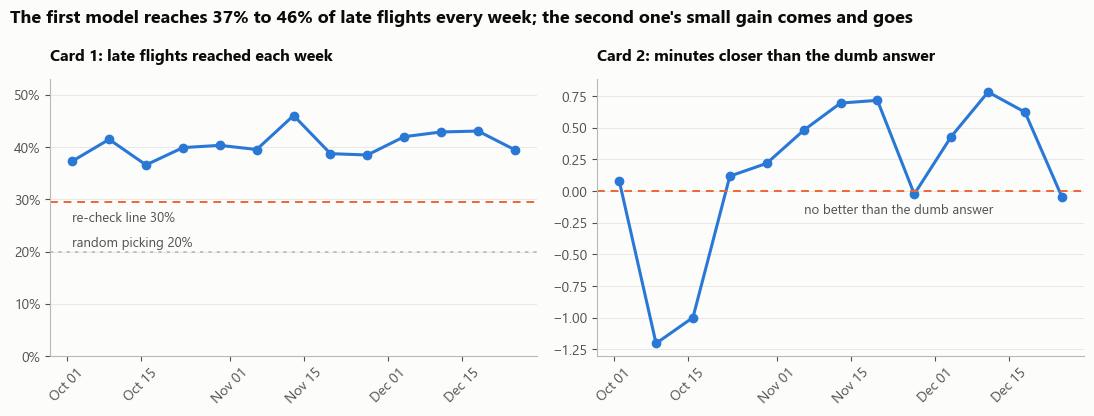

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ax = axes[0]
ax.plot(full1["week_start"], full1["value"], color=viz.BLUE, linewidth=2.2, marker="o", markersize=6)
ax.axhline(trigger1, color=viz.ORANGE, linewidth=1.4, linestyle=(0, (4, 3)))
ax.annotate(f"re-check line {trigger1:.0%}", (full1["week_start"].iloc[0], trigger1), xytext=(0, -14), textcoords="offset points", fontsize=9.5, color=viz.INK_2)
ax.axhline(random_recall1, color=viz.GREY, linewidth=1.2, linestyle=(0, (2, 3)))
ax.annotate("random picking 20%", (full1["week_start"].iloc[0], random_recall1), xytext=(0, 4), textcoords="offset points", fontsize=9.5, color=viz.INK_2)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0)); ax.set_ylim(0, max(full1["value"].max() * 1.15, 0.5))
ax.set_title("Card 1: late flights reached each week", fontsize=11.5); ax.tick_params(axis="x", labelrotation=45)
ax = axes[1]
ax.plot(full2["week_start"], full2["value"], color=viz.BLUE, linewidth=2.2, marker="o", markersize=6)
ax.axhline(0, color=viz.ORANGE, linewidth=1.4, linestyle=(0, (4, 3)))
ax.annotate("no better than the dumb answer", (full2["week_start"].iloc[5], 0), xytext=(0, -16), textcoords="offset points", fontsize=9.5, color=viz.INK_2)
ax.set_title("Card 2: minutes closer than the dumb answer", fontsize=11.5); ax.tick_params(axis="x", labelrotation=45)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
fig.suptitle(f"The first model reaches {full1['value'].min():.0%} to {full1['value'].max():.0%} of late flights every week; the second one's small gain comes and goes",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
chart_weekly = viz.save_figure(fig, "07_weekly_scores.png")
plt.show()

## The two cards
Each card has 11 lines. Every number is computed above and filled in by code.

In [9]:
worst_hour = errors_a[(errors_a["dimension"] == "hour_band") & (errors_a["metric"] == "recall")].sort_values("value")
worst_carrier = errors_a[(errors_a["dimension"] == "carrier") & (errors_a["metric"] == "recall") & (errors_a["n"] >= 2000)].sort_values("value")
dom = findings.loc[findings["finding"].str.contains("domino"), "number"].iloc[0]
pr = res_a["pr_auc"]
known_share = feat["prev_known"].mean()
p90_by_tenth = sec.assign(r=pd.qcut(sec["pred"].rank(method="first"), 10, labels=False)).groupby("r")["y_true"].quantile(0.9)
p90_low, p90_top = p90_by_tenth.iloc[0], p90_by_tenth.iloc[-1]
errors_b_carrier = errors_b[(errors_b["dimension"] == "carrier") & (errors_b["metric"] == "mae_model") & (errors_b["n"] >= 2000)].sort_values("value")
tail = res_b.loc["gradient_boosting", "mae_minutes_without_top1pct"]

valid_a = pd.read_csv(common.REPORTS / "06a_valid_results.csv").pivot(index="model", columns="metric", values="value")["pr_auc"]
REAL = ["logistic_regression", "gradient_boosting", "neural_network"]
best_a = valid_a[REAL].idxmax()                 # the model notebook 06a chose on the valid months
others = [m for m in REAL if m != best_a]
MODEL_TEXT = {"neural_network": "A neural network (two small hidden layers)", "gradient_boosting": "Gradient boosting (many small decision trees)",
              "logistic_regression": "Logistic regression (a simple weighted-evidence model)"}
NICE = {"neural_network": "neural network", "gradient_boosting": "gradient boosting", "logistic_regression": "logistic regression"}
card1 = {
    "Prediction": f"Will this flight leave more than 15 minutes late, or be cancelled? Predicted for every scheduled flight, 2 hours before its scheduled departure.",
    "Metric and why": f"The share of all late-or-cancelled flights we reach when we warn the riskiest 1 flight in 5 (recall), with precision next to it. A missed late flight can strand a client or break a connection; a needless warning costs one message.",
    "Cut-off": f"Two hours before each departure, warn the flight if its risk is above the cut-off set from the risk scores of the previous 7 days (the score of the riskiest {WARN_SHARE:.0%} of those flights; it needs no outcomes and no future flights). Run like this from the 8th day of October to the end of December, it warned {share_live:.0%} of the flights and reached {recall_live:.0%} of the late or cancelled ones, {precision_live:.0%} of the warnings being right. If each hour were ranked on its own, with no history, the reach would fall to {recall_hour:.0%}; ranking the whole quarter at once (risk above {threshold1:.2f}), which no live system can do, reaches {recall1:.0%}. Chosen by capacity, assuming the agency can warn about 1 flight in 5 (to be confirmed), not by a fixed probability, because the scores ran high in the calm months ({calib['mean_predicted'].mul(calib['flights']).sum() / calib['flights'].sum():.0%} predicted against {base1:.0%} real).",
    "Action": "Warn those clients and check their connections. The list is the same for every destination; the advice differs by type: steady regional routes, a short heads-up and a backup for tight connections; afternoon build-up routes, offer a morning flight or a longer connection; thin routes, offer a flexible ticket and rebook early.",
    "Value": f"On the held-out months (October to December): {k1:,} of {n1:,} flights are warned (1 in 5). {precision1:.0%} of them are really late or cancelled (against {base1:.0%} of all flights) and together they hold {recall1:.0%} of all late or cancelled flights. Picking {k1:,} flights at random would reach {random_recall1:.0%}: the model reaches {recall1 / random_recall1:.1f} times more. The dumb answer \"nobody is late\" warns nobody and reaches 0%.",
    "Model": f"{MODEL_TEXT[best_a]} on 18 columns known 2 hours before: hour, weekday, airline, airport, destination type, distance, airport crowding, plane age and seats, the weather 2 hours earlier, and the delay of the same plane's earlier flight. Trained on the flights of January to September 2023.",
    "Score": f"PR-AUC {pr[best_a]:.2f} on October-December, against {pr['dumb_never_late']:.2f} for the dumb answer and {pr['hour_rule']:.2f} for a simple hour-of-day rule. The other two models, {NICE[others[0]]} ({pr[others[0]]:.2f}) and {NICE[others[1]]} ({pr[others[1]]:.2f}), score about the same.",
    "Weak spots": f"It reaches only {worst_hour.iloc[0]['value']:.0%} of the late flights in the {worst_hour.iloc[0]['level']} band, but {worst_hour.iloc[-1]['value']:.0%} in the {worst_hour.iloc[-1]['level']} band. By airline the reach goes from {worst_carrier.iloc[0]['value']:.0%} ({airline_names[worst_carrier.iloc[0]['level']]}) to {worst_carrier.iloc[-1]['value']:.0%} ({airline_names[worst_carrier.iloc[-1]['level']]}). Risk scores run too high in calm months, so use the ranking, not the percentage.",
    "Re-check when": f"Every week, once it is over: rank that week's flights by risk, warn the riskiest fifth and measure how many of the late or cancelled flights they hold (the weekly reach). The line comes from the July to September validation weeks (median weekly reach {median_recall:.0%}; the line is 80% of it, {trigger1:.0%}), not from the held-out weeks. Retrain when the weekly reach falls below {trigger1:.0%} for two weeks in a row. In October-December the weekly reach was between {full1['value'].min():.0%} and {full1['value'].max():.0%}, and the rule {rule_text(twice_in_a_row)}.",
    "Human check": "Before calling a client, a person looks at the plane's earlier flights and the weather, and handles clients on tight connections first. Nothing is cancelled or rebooked automatically.",
    "Finding": f"{dom} This is already known two hours before departure for the {known_share:.0%} of flights whose plane's earlier flight had left at least 2 hours before.",
}
card2 = {
    "Prediction": "How many minutes late will this flight leave? Predicted for every flight that leaves, 2 hours before its scheduled departure. (Cancelled flights are covered by card 1.)",
    "Metric and why": "The average error in minutes (MAE), with the median error next to it. Clients are told a number of minutes, so the error is read in minutes. A few flights of 5 to 30 hours weigh heavily in the average, which is why the median is shown too.",
    "Cut-off": f"Check the connections of the {CHECK_SHARE:.0%} of flights with the highest predicted delay (predicted delay above {threshold2:.0f} minutes in October-December). Chosen by capacity, assuming the agency can check 1 flight in 20 (to be confirmed). A \"long\" delay means {LONG_DELAY} minutes or more.",
    "Action": "For flagged flights: tell the client to expect a long delay, check the connection, and prepare a backup flight. Do not change the booking until a person has confirmed.",
    "Value": f"On the held-out months: {k2:,} of {n2:,} flights are flagged (1 in 20). {precision2:.0%} of them really leave {LONG_DELAY} minutes or more late, against {base2:.0%} of all flights ({precision2 / base2:.1f} times more), and they hold {recall2:.0%} of all long delays (picking at random would reach {k2 / n2:.0%}). On average the prediction is {mae_dumb - mae_model:.2f} minutes closer than the dumb answer ({mae_model:.2f} against {mae_dumb:.2f} minutes).",
    "Model": "Gradient boosting (many small decision trees, trained to minimise the absolute error) on the same 18 columns known 2 hours before, trained on January to September 2023. It predicts the usual delay of flights like this one.",
    "Score": f"Average error {mae_model:.2f} minutes against {mae_dumb:.2f} for the dumb answer (every flight leaves {abs(usual):.0f} minutes {'early' if usual < 0 else 'late'}); median error {med_model:.1f} against {med_dumb:.1f} minutes. A straight-line model (ridge) is at {res_b.loc['ridge', 'mae_minutes']:.2f} minutes.",
    "Weak spots": f"The gain in average error is small: the biggest delays (a handful of flights) cannot be foreseen and dominate the average. Without the 1% most delayed flights the model's average error is {tail:.1f} minutes. Errors differ by airline, from {errors_b_carrier.iloc[0]['value']:.0f} minutes ({airline_names[errors_b_carrier.iloc[0]['level']]}) to {errors_b_carrier.iloc[-1]['value']:.0f} minutes ({airline_names[errors_b_carrier.iloc[-1]['level']]}). Predicting the usual delay means it flags risk, not certainty.",
    "Re-check when": f"Every week, comparing the model's average error with the dumb answer's. In the held-out weeks the model beat the dumb answer in {int((full2['value'] > 0).sum())} of {len(full2)} full weeks, and the rule below {rule_text(fired2)}: the gain is fragile. Retrain, or drop the model, when it is no better than the dumb answer for two weeks in a row.",
    "Human check": "A person confirms the plane's earlier delay and the airline's own status before telling a client to expect a long delay. Clients on tight connections come first.",
    "Finding": f"Delay is a matter of risk, not certainty. In the tenth of flights with the highest predicted delay, one flight in ten leaves more than {p90_top:.0f} minutes late, against {p90_low:.0f} minutes in the lowest tenth, even though the usual flight in both leaves close to schedule.",
}
rows = []
for name, card in [("first", card1), ("second", card2)]:
    for i, (line, text) in enumerate(card.items(), start=1):
        rows.append(dict(card=name, line_no=i, line=line, text=text))
cards = pd.DataFrame(rows)
cards.to_csv(common.REPORTS / "07_cards.csv", index=False)
assert (cards.groupby("card").size() == 11).all() and cards["text"].str.len().gt(15).all()

def render(title, card):
    return f"### {title}\n\n| # | Line | What we write |\n|---|---|---|\n" + "\n".join(f"| {i} | **{k}** | {v} |" for i, (k, v) in enumerate(card.items(), start=1))
display(Markdown(render("Decision card 1: will this flight be late or cancelled?", card1)))

### Decision card 1: will this flight be late or cancelled?

| # | Line | What we write |
|---|---|---|
| 1 | **Prediction** | Will this flight leave more than 15 minutes late, or be cancelled? Predicted for every scheduled flight, 2 hours before its scheduled departure. |
| 2 | **Metric and why** | The share of all late-or-cancelled flights we reach when we warn the riskiest 1 flight in 5 (recall), with precision next to it. A missed late flight can strand a client or break a connection; a needless warning costs one message. |
| 3 | **Cut-off** | Two hours before each departure, warn the flight if its risk is above the cut-off set from the risk scores of the previous 7 days (the score of the riskiest 20% of those flights; it needs no outcomes and no future flights). Run like this from the 8th day of October to the end of December, it warned 20% of the flights and reached 41% of the late or cancelled ones, 28% of the warnings being right. If each hour were ranked on its own, with no history, the reach would fall to 34%; ranking the whole quarter at once (risk above 0.30), which no live system can do, reaches 40%. Chosen by capacity, assuming the agency can warn about 1 flight in 5 (to be confirmed), not by a fixed probability, because the scores ran high in the calm months (22% predicted against 14% real). |
| 4 | **Action** | Warn those clients and check their connections. The list is the same for every destination; the advice differs by type: steady regional routes, a short heads-up and a backup for tight connections; afternoon build-up routes, offer a morning flight or a longer connection; thin routes, offer a flexible ticket and rebook early. |
| 5 | **Value** | On the held-out months (October to December): 20,894 of 104,469 flights are warned (1 in 5). 28% of them are really late or cancelled (against 14% of all flights) and together they hold 40% of all late or cancelled flights. Picking 20,894 flights at random would reach 20%: the model reaches 2.0 times more. The dumb answer "nobody is late" warns nobody and reaches 0%. |
| 6 | **Model** | A neural network (two small hidden layers) on 18 columns known 2 hours before: hour, weekday, airline, airport, destination type, distance, airport crowding, plane age and seats, the weather 2 hours earlier, and the delay of the same plane's earlier flight. Trained on the flights of January to September 2023. |
| 7 | **Score** | PR-AUC 0.29 on October-December, against 0.14 for the dumb answer and 0.18 for a simple hour-of-day rule. The other two models, logistic regression (0.28) and gradient boosting (0.30), score about the same. |
| 8 | **Weak spots** | It reaches only 7% of the late flights in the Morning (before noon) band, but 70% in the Evening (6 pm on) band. By airline the reach goes from 19% (American Airlines) to 63% (JetBlue Airways). Risk scores run too high in calm months, so use the ranking, not the percentage. |
| 9 | **Re-check when** | Every week, once it is over: rank that week's flights by risk, warn the riskiest fifth and measure how many of the late or cancelled flights they hold (the weekly reach). The line comes from the July to September validation weeks (median weekly reach 37%; the line is 80% of it, 30%), not from the held-out weeks. Retrain when the weekly reach falls below 30% for two weeks in a row. In October-December the weekly reach was between 37% and 46%, and the rule would not have fired. |
| 10 | **Human check** | Before calling a client, a person looks at the plane's earlier flights and the weather, and handles clients on tight connections first. Nothing is cancelled or rebooked automatically. |
| 11 | **Finding** | When the same plane's earlier flight left more than 15 minutes late, 61% of the next flights are late or cancelled, against 25% when it left on time. This is already known two hours before departure for the 29% of flights whose plane's earlier flight had left at least 2 hours before. |

In [10]:
display(Markdown(render("Decision card 2: how many minutes late will this flight leave?", card2)))

### Decision card 2: how many minutes late will this flight leave?

| # | Line | What we write |
|---|---|---|
| 1 | **Prediction** | How many minutes late will this flight leave? Predicted for every flight that leaves, 2 hours before its scheduled departure. (Cancelled flights are covered by card 1.) |
| 2 | **Metric and why** | The average error in minutes (MAE), with the median error next to it. Clients are told a number of minutes, so the error is read in minutes. A few flights of 5 to 30 hours weigh heavily in the average, which is why the median is shown too. |
| 3 | **Cut-off** | Check the connections of the 5% of flights with the highest predicted delay (predicted delay above 14 minutes in October-December). Chosen by capacity, assuming the agency can check 1 flight in 20 (to be confirmed). A "long" delay means 45 minutes or more. |
| 4 | **Action** | For flagged flights: tell the client to expect a long delay, check the connection, and prepare a backup flight. Do not change the booking until a person has confirmed. |
| 5 | **Value** | On the held-out months: 5,212 of 104,245 flights are flagged (1 in 20). 21% of them really leave 45 minutes or more late, against 6% of all flights (3.4 times more), and they hold 17% of all long delays (picking at random would reach 5%). On average the prediction is 0.14 minutes closer than the dumb answer (13.12 against 13.27 minutes). |
| 6 | **Model** | Gradient boosting (many small decision trees, trained to minimise the absolute error) on the same 18 columns known 2 hours before, trained on January to September 2023. It predicts the usual delay of flights like this one. |
| 7 | **Score** | Average error 13.12 minutes against 13.27 for the dumb answer (every flight leaves 2 minutes early); median error 4.5 against 5.0 minutes. A straight-line model (ridge) is at 13.46 minutes. |
| 8 | **Weak spots** | The gain in average error is small: the biggest delays (a handful of flights) cannot be foreseen and dominate the average. Without the 1% most delayed flights the model's average error is 10.6 minutes. Errors differ by airline, from 7 minutes (Republic Airline) to 21 minutes (JetBlue Airways). Predicting the usual delay means it flags risk, not certainty. |
| 9 | **Re-check when** | Every week, comparing the model's average error with the dumb answer's. In the held-out weeks the model beat the dumb answer in 9 of 13 full weeks, and the rule below would have fired once: the gain is fragile. Retrain, or drop the model, when it is no better than the dumb answer for two weeks in a row. |
| 10 | **Human check** | A person confirms the plane's earlier delay and the airline's own status before telling a client to expect a long delay. Clients on tight connections come first. |
| 11 | **Finding** | Delay is a matter of risk, not certainty. In the tenth of flights with the highest predicted delay, one flight in ten leaves more than 74 minutes late, against 0 minutes in the lowest tenth, even though the usual flight in both leaves close to schedule. |

## What a manager can do with this
- **Card 1** works as a rolling warning list: two hours before each departure, score the flight and warn it if its risk is above the cut-off of the previous 7 days (the key inputs, the weather and the earlier flight, only exist then, not the day before), and add the extra human checks. Measured on the held-out months from the 8th day on, this reaches the share shown on the card; ranking each hour on its own is weaker.
- **Card 2** is a complement, not a replacement: it helps order the connection checks. Its gain in average error is small, and the card says so.
- Both cards rest on **two capacity assumptions** (1 flight in 5 warned, 1 in 20 checked) that the agency must confirm. If the capacity changes, change `WARN_SHARE` or `CHECK_SHARE` at the top and rerun: every number follows.